
# Step 6. Early Detection — Cox Proportional Hazards

## 1. Overview

This notebook demonstrates the Cox proportional hazards training and application workflow using 100 demonstration participants.

The existing `T2D` column represents type 2 diabetes Case/Control status at follow-up, not baseline.

Because baseline disease status and longitudinal follow-up time are not available in the demonstration dataset, these variables are simulated.

The original follow-up T2D labels are preserved without modification.

No new follow-up disease labels are generated.

## 2. Synthetic Baseline and Follow-up Data

For each participant:

1. Preserve the existing follow-up Case/Control status.
2. Generate a synthetic baseline T2D status.
3. Generate a baseline-to-follow-up interval in weeks.
4. Establish the Cox risk set among participants without T2D at baseline.

To maintain consistency, follow-up controls are assigned baseline control status. A predefined proportion of follow-up cases are assigned baseline case status, while the remaining follow-up cases are assigned baseline control status.

Among baseline controls, follow-up cases are coded as `event = 1`, and follow-up controls are coded as `event = 0`.

No additional loss-to-follow-up or competing-event process is simulated. Participants with `event = 0` are treated as right-censored at their follow-up visit, as required by the standard Cox model.

The follow-up visit represents the observation time of disease status, rather than a verified exact onset date.

## 3. Cox Model

The Cox model uses:

- AGE
- SEX
- Familyall_numeric
- PRS_Score

The PRS is the combined score already rescaled to 0–1 in Step 4.

Training1 and Training2 participants who are controls at baseline are used for Cox fitting.

Validation and Testing participants who are controls at baseline are used for model application.

The demonstration uses a small positive penalizer for stability with its limited sample size.

## 4. Cox Application

The fitted model is saved and subsequently reloaded without retraining.

For eligible Validation and Testing participants, the notebook generates:

- Predicted T2D risk at individual follow-up.
- Predicted T2D-free survival at individual follow-up.
- Predicted T2D risk at a common time horizon.
- Predicted median T2D-free survival time, if estimable.
- Restricted mean T2D-free survival time (RMST) within the common horizon.

An optional final illustration compares Cox predictions across XGBoost and TabPFN classification groups, similar to the original study's Figure 5.

Fasting glucose and HbA1c comparisons are omitted because those longitudinal laboratory measurements are not included in the demonstration data.

All synthetic follow-up results are illustrative and do not represent the original study's observed longitudinal outcomes.

## 5. Outputs

- `Outputs/Step6_Early_Detection/Demo_Cox_Data.csv`
- `Outputs/Step6_Early_Detection/Demo_Cox_Model.joblib`
- `Outputs/Step6_Early_Detection/Demo_Cox_Application.csv`
- `Outputs/Step6_Early_Detection/Demo_Cox_Application.png`



## Environment Setup

This notebook uses the shared `t2d-gpu` Conda environment defined in `environments/gpu.yml`.

Cox fitting and prediction run on CPU; a GPU is not required for the survival analysis.

### New installation

From the downloaded repository root:

```bash
conda env create -f environments/gpu.yml

conda run -n t2d-gpu python -m ipykernel install \
    --user --name t2d-gpu --display-name "T2D GPU"
```

### Existing environment

If the environment already exists but lifelines is unavailable:

```bash
conda run -n t2d-gpu python -m pip install lifelines==0.30.0 joblib==1.4.2
```

Open this notebook and select **Kernel → Change Kernel → T2D GPU**.

Before executing the notebook, complete Step 4 to create the participant-level feature dataset. The Step 5 XGBoost and TabPFN prediction files are also required for the final early-detection illustration.


In [7]:
# ============================================================
# 0. Cox Demo — Configuration and Data Loading
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from lifelines import CoxPHFitter
from IPython.display import display


# ------------------------------------------------------------
# 0.1 Paths
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd().resolve()

INPUT_FILE = (
    PROJECT_ROOT
    / "Outputs/Step4_Feature_Assembly"
    / "Multimodal_100_samples_PRSCSx_EqualWeight.csv"
)

OUT = PROJECT_ROOT / "Outputs/Step6_Early_Detection"
OUT.mkdir(parents=True, exist_ok=True)

COX_DATA_FILE = OUT / "Demo_Cox_Data.csv"
COX_MODEL_FILE = OUT / "Demo_Cox_Model.joblib"
COX_APPLY_FILE = OUT / "Demo_Cox_Application.csv"
COX_FIGURE_FILE = OUT / "Demo_Cox_Application.png"


# ------------------------------------------------------------
# 0.2 Simulation parameters
# ------------------------------------------------------------

SEED = 20261103

BASELINE_DATE = "2020-01-01"

FOLLOWUP_MIN_WEEKS = 156
FOLLOWUP_MAX_WEEKS = 416

# Among follow-up cases, proportion simulated
# as having T2D already at baseline.
BASELINE_CASE_FRACTION = 0.20


# ------------------------------------------------------------
# 0.3 Cox parameters
# ------------------------------------------------------------

COVARIATES = [
    "AGE",
    "SEX",
    "Familyall_numeric",
    "PRS_Score",
]

COX_TRAIN_SPLITS = ["training1", "training2"]
COX_APPLY_SPLITS = ["validation", "testing"]

# Original study: 0.0
# Demo: positive penalizer for numerical stability
COX_PENALIZER = 0.10

# Common prediction horizon
HORIZON_QUANTILE = 0.90


# ------------------------------------------------------------
# 0.4 Load existing participant data
# ------------------------------------------------------------

assert INPUT_FILE.is_file(), INPUT_FILE

raw = pd.read_csv(
    INPUT_FILE,
    dtype={"Demo_ID": str}
)

required = [
    "Demo_ID", "Dataset", "T2D", *COVARIATES
]

missing = set(required) - set(raw.columns)
assert not missing, f"Missing columns: {missing}"

assert len(raw) == 100
assert raw["Demo_ID"].is_unique

raw["Dataset"] = (
    raw["Dataset"]
    .astype(str)
    .str.strip()
    .str.lower()
)

assert raw["Dataset"].value_counts().to_dict() == {
    "training1": 32,
    "training2": 32,
    "validation": 16,
    "testing": 20,
}

# IMPORTANT:
# Existing T2D is FOLLOW-UP status, not baseline.
raw["T2D"] = pd.to_numeric(
    raw["T2D"], errors="raise"
).astype(int)

assert raw["T2D"].isin([0, 1]).all()

for col in COVARIATES:
    raw[col] = pd.to_numeric(
        raw[col], errors="raise"
    )

assert np.isfinite(
    raw[COVARIATES].to_numpy(dtype=float)
).all()

assert raw["PRS_Score"].between(0, 1).all()

print("=" * 65)
print("COX DEMO — INPUT DATA")
print("=" * 65)

print("Participants:", len(raw))
print("T2D definition: FOLLOW-UP Case/Control")

display(
    pd.crosstab(
        raw["Dataset"],
        raw["T2D"]
    ).rename(columns={
        0: "Follow-up Control",
        1: "Follow-up Case"
    })
)

COX DEMO — INPUT DATA
Participants: 100
T2D definition: FOLLOW-UP Case/Control


T2D,Follow-up Control,Follow-up Case
Dataset,,
testing,10,10
training1,16,16
training2,16,16
validation,8,8


In [8]:
# ============================================================
# 1. Simulate Baseline Status and Follow-up Time
# ============================================================

rng = np.random.default_rng(SEED)

cox_data = (
    raw[["Demo_ID", "Dataset", "T2D", *COVARIATES]]
    .sort_values("Demo_ID")
    .reset_index(drop=True)
    .copy()
)


# ------------------------------------------------------------
# 1.1 Preserve original follow-up phenotype
# ------------------------------------------------------------

cox_data = cox_data.rename(
    columns={"T2D": "Followup_T2D"}
)

cox_data["Followup_Status"] = np.where(
    cox_data["Followup_T2D"].eq(1),
    "Case",
    "Control"
)


# ------------------------------------------------------------
# 1.2 Simulate baseline T2D status
# ------------------------------------------------------------

# All follow-up controls must be baseline controls.
cox_data["Baseline_T2D"] = 0

# Some follow-up cases may already have T2D at baseline.
case_indices = np.flatnonzero(
    cox_data["Followup_T2D"].to_numpy() == 1
)

n_baseline_cases = int(
    round(
        len(case_indices)
        * BASELINE_CASE_FRACTION
    )
)

if n_baseline_cases > 0:

    selected = rng.choice(
        case_indices,
        size=n_baseline_cases,
        replace=False
    )

    cox_data.loc[
        selected,
        "Baseline_T2D"
    ] = 1

cox_data["Baseline_Status"] = np.where(
    cox_data["Baseline_T2D"].eq(1),
    "Case",
    "Control"
)


# ------------------------------------------------------------
# 1.3 Generate baseline-to-follow-up interval
# ------------------------------------------------------------

cox_data["time_weeks"] = rng.integers(
    FOLLOWUP_MIN_WEEKS,
    FOLLOWUP_MAX_WEEKS + 1,
    size=len(cox_data)
).astype(float)

baseline_date = pd.Timestamp(BASELINE_DATE)

cox_data["Baseline_Date"] = baseline_date

cox_data["Followup_Date"] = (
    baseline_date
    + pd.to_timedelta(
        cox_data["time_weeks"] * 7,
        unit="D"
    )
)


# ------------------------------------------------------------
# 1.4 Construct Cox risk set and event
# ------------------------------------------------------------

# Only baseline controls are at risk for incident T2D.
cox_data["Eligible_Cox"] = (
    cox_data["Baseline_T2D"] == 0
)

# Follow-up labels are preserved:
# Baseline Control -> Follow-up Case: event=1
# Baseline Control -> Follow-up Control: event=0
# Baseline Case: excluded from Cox fitting/application

cox_data["event"] = pd.Series(
    pd.NA,
    index=cox_data.index,
    dtype="Int64"
)

eligible = cox_data["Eligible_Cox"]

cox_data.loc[
    eligible,
    "event"
] = cox_data.loc[
    eligible,
    "Followup_T2D"
].to_numpy(dtype=int)


# ------------------------------------------------------------
# 1.5 Verify logical consistency
# ------------------------------------------------------------

assert not (
    cox_data["Baseline_T2D"].eq(1)
    & cox_data["Followup_T2D"].eq(0)
).any()

assert (
    cox_data.loc[
        cox_data["Eligible_Cox"], "event"
    ].astype(int).to_numpy()
    ==
    cox_data.loc[
        cox_data["Eligible_Cox"], "Followup_T2D"
    ].to_numpy()
).all()

assert (
    cox_data["time_weeks"] > 0
).all()

assert len(cox_data) == 100


# ------------------------------------------------------------
# 1.6 Save simulated longitudinal data
# ------------------------------------------------------------

cox_data.to_csv(
    COX_DATA_FILE,
    index=False
)


# ------------------------------------------------------------
# 1.7 Display
# ------------------------------------------------------------

print("=" * 65)
print("SYNTHETIC BASELINE / FOLLOW-UP DATA")
print("=" * 65)

print("Total participants:", len(cox_data))
print("Cox-eligible:", int(eligible.sum()))

print("\nBaseline vs Follow-up:")

display(
    pd.crosstab(
        cox_data["Baseline_Status"],
        cox_data["Followup_Status"],
        margins=True
    )
)

print("\nCox risk set by Dataset:")

display(
    cox_data.loc[eligible]
    .groupby("Dataset")["event"]
    .agg(N="size", Events="sum")
)

print("\nSample preview:")

display(
    cox_data[
        [
            "Demo_ID",
            "Dataset",
            "Baseline_Status",
            "Followup_Status",
            "time_weeks",
            "event",
        ]
    ].head(10)
)

print("\nSaved:", COX_DATA_FILE)

SYNTHETIC BASELINE / FOLLOW-UP DATA
Total participants: 100
Cox-eligible: 90

Baseline vs Follow-up:


Followup_Status,Case,Control,All
Baseline_Status,,,
Case,10,0,10
Control,40,50,90
All,50,50,100



Cox risk set by Dataset:


,N,Events
Dataset,,
testing,17,7
training1,27,11
training2,31,15
validation,15,7



Sample preview:


,Demo_ID,Dataset,Baseline_Status,Followup_Status,time_weeks,event
0,D001,training2,Control,Control,365.0,0
1,D002,testing,Control,Control,174.0,0
2,D003,training2,Control,Case,219.0,1
3,D004,training1,Control,Case,354.0,1
4,D005,training2,Control,Case,271.0,1
5,D006,training2,Control,Case,377.0,1
6,D007,testing,Control,Control,261.0,0
7,D008,training2,Control,Case,190.0,1
8,D009,testing,Control,Case,258.0,1
9,D010,training1,Control,Control,349.0,0



Saved: [LOCAL_PATH]


In [9]:
# ============================================================
# 2. Fit Demo Cox and Save Model
# ============================================================

# ------------------------------------------------------------
# 2.1 Select Cox training participants
# ------------------------------------------------------------

train = cox_data.loc[
    cox_data["Eligible_Cox"]
    & cox_data["Dataset"].isin(COX_TRAIN_SPLITS)
].copy()

assert len(train) > len(COVARIATES)

assert train["event"].notna().all()

train["event"] = train["event"].astype(int)

n_events = int(train["event"].sum())
n_controls = int((train["event"] == 0).sum())

if n_events < 2 or n_controls < 2:
    raise ValueError(
        "Insufficient Cox training events or controls. "
        "Check the demonstration sample distribution."
    )


# ------------------------------------------------------------
# 2.2 Prepare covariates
# ------------------------------------------------------------

cox_medians = train[COVARIATES].median()

assert cox_medians.notna().all()

train[COVARIATES] = (
    train[COVARIATES]
    .fillna(cox_medians)
)

fit_df = train[
    ["time_weeks", "event", *COVARIATES]
].copy()

assert np.isfinite(
    fit_df.to_numpy(dtype=float)
).all()


# ------------------------------------------------------------
# 2.3 Cox proportional hazards model
# ------------------------------------------------------------

cph = CoxPHFitter(
    penalizer=COX_PENALIZER
)

cph.fit(
    fit_df,
    duration_col="time_weeks",
    event_col="event",
    show_progress=False
)


# ------------------------------------------------------------
# 2.4 Define common prediction horizon
# ------------------------------------------------------------

TAU = float(
    train["time_weeks"].quantile(
        HORIZON_QUANTILE
    )
)

assert TAU > 0


# ------------------------------------------------------------
# 2.5 Save model and preprocessing settings
# ------------------------------------------------------------

cox_bundle = {
    "model": cph,
    "covariates": COVARIATES,
    "median": cox_medians.to_dict(),
    "time_unit": "weeks",
    "prediction_horizon_weeks": TAU,
    "baseline_status": "Synthetic",
    "followup_outcome": "Existing T2D",
    "training_splits": COX_TRAIN_SPLITS,
}

joblib.dump(
    cox_bundle,
    COX_MODEL_FILE
)


# ------------------------------------------------------------
# 2.6 Display model output
# ------------------------------------------------------------

print("=" * 65)
print("DEMO COX MODEL")
print("=" * 65)

print("Training participants:", len(train))
print("Follow-up Cases (events):", n_events)
print("Follow-up Controls:", n_controls)

print("Prediction horizon:", round(TAU, 2), "weeks")

print(
    "Training C-index:",
    round(float(cph.concordance_index_), 4)
)

display(
    cph.summary[
        [
            "coef",
            "exp(coef)",
            "exp(coef) lower 95%",
            "exp(coef) upper 95%",
            "p",
        ]
    ]
)

print("\nModel saved:", COX_MODEL_FILE)

DEMO COX MODEL
Training participants: 58
Follow-up Cases (events): 26
Follow-up Controls: 32
Prediction horizon: 378.8 weeks
Training C-index: 0.639


,coef,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%,p
covariate,,,,,
AGE,0.001151,1.001151,0.975043,1.027959,0.931994
SEX,-0.180447,0.834897,0.404613,1.722765,0.625381
Familyall_numeric,-0.363239,0.695420,0.292544,1.653117,0.410969
PRS_Score,-0.861711,0.422439,0.072018,2.477920,0.339748



Model saved: [LOCAL_PATH]


In [10]:
# ============================================================
# 3. Apply Saved Cox Model — No Retraining
# ============================================================

# ------------------------------------------------------------
# 3.1 Load existing model
# ------------------------------------------------------------

bundle = joblib.load(COX_MODEL_FILE)

cox_model = bundle["model"]
cov_cols = bundle["covariates"]

TAU = float(
    bundle["prediction_horizon_weeks"]
)

medians = pd.Series(
    bundle["median"],
    dtype=float
)


# ------------------------------------------------------------
# 3.2 Select application participants
# ------------------------------------------------------------

apply_df = cox_data.loc[
    cox_data["Eligible_Cox"]
    & cox_data["Dataset"].isin(COX_APPLY_SPLITS)
].copy()

apply_df = (
    apply_df
    .sort_values("Demo_ID")
    .reset_index(drop=True)
)

assert not apply_df.empty
assert apply_df["Demo_ID"].is_unique

X_apply = (
    apply_df[cov_cols]
    .copy()
    .fillna(medians)
)

assert np.isfinite(
    X_apply.to_numpy(dtype=float)
).all()


# ------------------------------------------------------------
# 3.3 Partial hazard
# ------------------------------------------------------------

partial_hazard = (
    cox_model.predict_partial_hazard(X_apply)
    .to_numpy(dtype=float)
    .reshape(-1)
)

assert (partial_hazard > 0).all()


# ------------------------------------------------------------
# 3.4 Baseline cumulative hazard
# ------------------------------------------------------------

baseline = (
    cox_model.baseline_cumulative_hazard_
    .iloc[:, 0]
)

T0 = baseline.index.to_numpy(dtype=float)
H0 = baseline.to_numpy(dtype=float)

if T0[0] > 0:
    T0 = np.r_[0.0, T0]
    H0 = np.r_[0.0, H0]

assert np.all(np.diff(T0) > 0)
assert np.all(np.diff(H0) >= -1e-10)


def baseline_hazard_at(times):
    """
    Step-function baseline cumulative hazard.
    Values outside the Cox observation range return NaN.
    """
    t = np.atleast_1d(
        np.asarray(times, dtype=float)
    )

    result = np.full(
        t.shape,
        np.nan,
        dtype=float
    )

    valid = (
        np.isfinite(t)
        & (t >= 0)
        & (t <= T0[-1])
    )

    if valid.any():

        index = (
            np.searchsorted(
                T0,
                t[valid],
                side="right"
            ) - 1
        )

        result[valid] = np.where(
            index >= 0,
            H0[np.maximum(index, 0)],
            0.0
        )

    return result


# ------------------------------------------------------------
# 3.5 Individual follow-up risk / survival
# ------------------------------------------------------------

followup_weeks = (
    apply_df["time_weeks"]
    .to_numpy(dtype=float)
)

H_followup = baseline_hazard_at(
    followup_weeks
)

survival_followup = np.exp(
    -partial_hazard * H_followup
)

risk_followup = (
    1.0 - survival_followup
)


# ------------------------------------------------------------
# 3.6 Risk at common time horizon
# ------------------------------------------------------------

assert 0 < TAU <= T0[-1]

H_tau = float(
    baseline_hazard_at([TAU])[0]
)

survival_tau = np.exp(
    -partial_hazard * H_tau
)

risk_tau = (
    1.0 - survival_tau
)


# ------------------------------------------------------------
# 3.7 Predicted median T2D-free survival time
# ------------------------------------------------------------

median_survival = (
    cox_model.predict_median(X_apply)
)

median_weeks = pd.to_numeric(
    median_survival,
    errors="coerce"
).to_numpy(dtype=float)

median_weeks = np.where(
    np.isfinite(median_weeks),
    median_weeks,
    np.nan
)


# ------------------------------------------------------------
# 3.8 RMST at common horizon
# ------------------------------------------------------------

time_grid = np.unique(
    np.r_[
        0.0,
        T0[(T0 > 0) & (T0 < TAU)],
        TAU
    ]
)

interval_widths = np.diff(time_grid)

H_left = baseline_hazard_at(
    time_grid[:-1]
)

interval_survival = np.exp(
    -H_left[:, None]
    * partial_hazard[None, :]
)

rmst_weeks = (
    interval_survival
    * interval_widths[:, None]
).sum(axis=0)


# ------------------------------------------------------------
# 3.9 Participant-level Cox application output
# ------------------------------------------------------------

cox_apply = apply_df[
    [
        "Demo_ID",
        "Dataset",
        "Baseline_Status",
        "Followup_Status",
        "time_weeks",
    ]
].copy()

cox_apply["Pred_Risk_at_Followup"] = risk_followup

cox_apply["Pred_Survival_at_Followup"] = (
    survival_followup
)

cox_apply["Pred_Risk_at_Tau"] = risk_tau

cox_apply["Pred_Survival_at_Tau"] = survival_tau

cox_apply["Pred_Median_Survival_Weeks"] = (
    median_weeks
)

cox_apply["RMST_Weeks_at_Tau"] = rmst_weeks

cox_apply["Tau_Weeks"] = TAU


# ------------------------------------------------------------
# 3.10 Save and display
# ------------------------------------------------------------

assert cox_apply["Pred_Risk_at_Tau"].between(
    0, 1
).all()

assert cox_apply["Pred_Survival_at_Tau"].between(
    0, 1
).all()

cox_apply.to_csv(
    COX_APPLY_FILE,
    index=False
)

print("=" * 65)
print("COX MODEL APPLICATION")
print("=" * 65)

print("Model loaded:", COX_MODEL_FILE.name)
print("No model refitting performed.")

print("\nPrediction horizon:", round(TAU, 2), "weeks")

print("\nApplication results:")

display(
    cox_apply[
        [
            "Demo_ID",
            "Dataset",
            "Followup_Status",
            "Pred_Risk_at_Followup",
            "Pred_Survival_at_Followup",
            "Pred_Risk_at_Tau",
            "RMST_Weeks_at_Tau",
        ]
    ].head(20).round(4)
)

print("\nSaved:", COX_APPLY_FILE)

COX MODEL APPLICATION
Model loaded: Demo_Cox_Model.joblib
No model refitting performed.

Prediction horizon: 378.8 weeks

Application results:


,Demo_ID,Dataset,Followup_Status,Pred_Risk_at_Followup,Pred_Survival_at_Followup,Pred_Risk_at_Tau,RMST_Weeks_at_Tau
0,D002,testing,Control,0.0229,0.9771,0.7068,317.7191
1,D007,testing,Control,0.1331,0.8669,0.4631,343.6513
2,D009,testing,Case,0.1097,0.8903,0.3970,349.4743
3,D017,testing,Control,0.4340,0.5660,0.5418,336.1901
4,D019,validation,Case,0.2491,0.7509,0.4887,341.2991
5,D027,testing,Control,0.9116,0.0884,0.5034,339.9091
6,D030,testing,Control,0.0161,0.9839,0.5755,332.7650
7,D032,testing,Case,0.1343,0.8657,0.3961,349.5461
8,D035,validation,Control,0.1671,0.8329,0.4724,342.8080
9,D036,testing,Case,0.0164,0.9836,0.5839,331.8961



Saved: [LOCAL_PATH]


COX APPLICATION GROUP COUNTS — TESTING


Group,G1: Case / Pred+,G3: Control / Pred+,G4: Control / Pred-,Other: Case / Pred-
Model,,,,
TabPFN,1,1,9,6
XGBoost,1,2,8,6


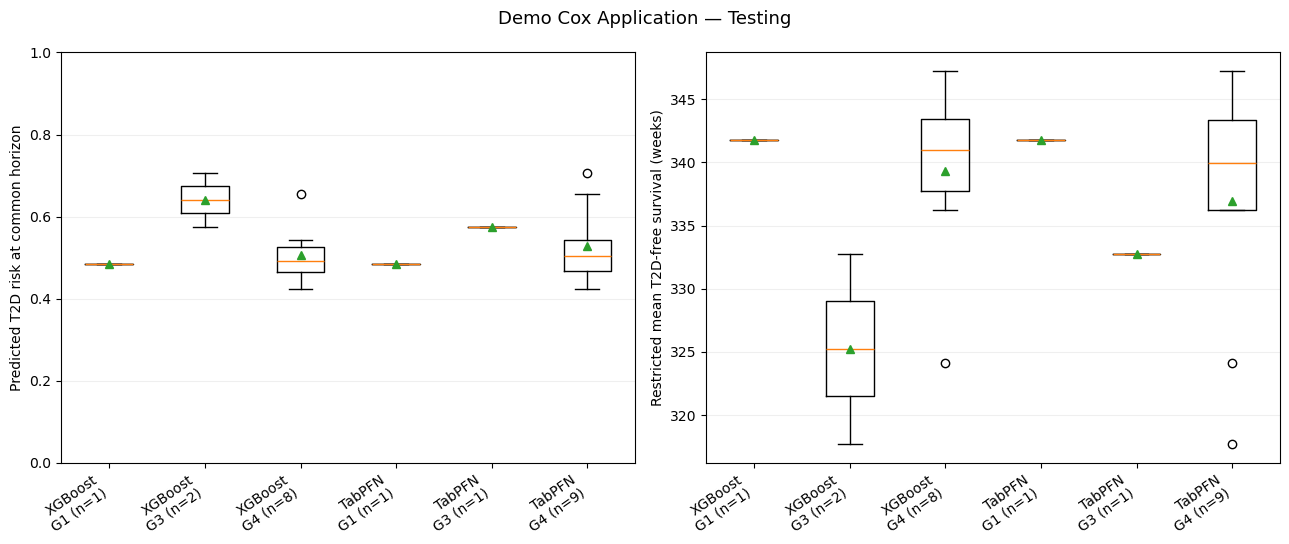


Saved: [LOCAL_PATH]


In [11]:
# ============================================================
# 4. Figure 5-style Cox Application Illustration
# ============================================================

PREDICTION_FILES = {
    "XGBoost": (
        PROJECT_ROOT
        / "Outputs/Step5_XGBoost/XGBoost_Predictions.csv"
    ),
    "TabPFN": (
        PROJECT_ROOT
        / "Outputs/Step5_TabPFN/TabPFN_Predictions.csv"
    ),
}

plot_parts = []


# ------------------------------------------------------------
# 4.1 Join ML classification with Cox application
# ------------------------------------------------------------

for model_name, path in PREDICTION_FILES.items():

    assert path.is_file(), path

    ml = pd.read_csv(
        path,
        dtype={"Demo_ID": str}
    )

    ml["Dataset"] = (
        ml["Dataset"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    assert ml["Demo_ID"].is_unique

    ml["Predicted_Label"] = pd.to_numeric(
        ml["Predicted_Label"],
        errors="raise"
    ).astype(int)

    assert ml["Predicted_Label"].isin([0, 1]).all()

    joined = cox_apply.loc[
        cox_apply["Dataset"].eq("testing")
    ].merge(
        ml[
            ["Demo_ID", "Dataset", "Predicted_Label"]
        ],
        on=["Demo_ID", "Dataset"],
        how="left",
        validate="one_to_one"
    )

    assert joined["Predicted_Label"].notna().all()

    is_case = joined["Followup_Status"].eq("Case")
    is_control = joined["Followup_Status"].eq("Control")
    pred_positive = joined["Predicted_Label"].eq(1)
    pred_negative = joined["Predicted_Label"].eq(0)

    joined["Group"] = np.select(
        [
            is_case & pred_positive,
            is_control & pred_positive,
            is_control & pred_negative,
            is_case & pred_negative,
        ],
        [
            "G1: Case / Pred+",
            "G3: Control / Pred+",
            "G4: Control / Pred-",
            "Other: Case / Pred-",
        ],
        default="Other"
    )

    joined["Model"] = model_name

    plot_parts.append(joined)


plot_df = pd.concat(
    plot_parts,
    ignore_index=True
)


# ------------------------------------------------------------
# 4.2 Group counts
# ------------------------------------------------------------

print("=" * 65)
print("COX APPLICATION GROUP COUNTS — TESTING")
print("=" * 65)

display(
    pd.crosstab(
        plot_df["Model"],
        plot_df["Group"]
    )
)


# ------------------------------------------------------------
# 4.3 Plot only the three original Figure 5 groups
# ------------------------------------------------------------

GROUP_ORDER = [
    "G1: Case / Pred+",
    "G3: Control / Pred+",
    "G4: Control / Pred-",
]

MODEL_ORDER = [
    "XGBoost",
    "TabPFN",
]

PLOT_METRICS = {
    "Pred_Risk_at_Tau":
        "Predicted T2D risk at common horizon",
    "RMST_Weeks_at_Tau":
        "Restricted mean T2D-free survival (weeks)",
}

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5.5)
)

for ax, (metric, ylabel) in zip(
    axes,
    PLOT_METRICS.items()
):

    values_list = []
    labels_list = []

    for model_name in MODEL_ORDER:

        for group_name in GROUP_ORDER:

            values = plot_df.loc[
                plot_df["Model"].eq(model_name)
                & plot_df["Group"].eq(group_name),
                metric
            ].dropna().to_numpy(dtype=float)

            if len(values) == 0:
                continue

            values_list.append(values)

            short_group = group_name.split(":")[0]

            labels_list.append(
                f"{model_name}\n"
                f"{short_group} (n={len(values)})"
            )

    if values_list:

        positions = np.arange(
            1,
            len(values_list) + 1
        )

        ax.boxplot(
            values_list,
            positions=positions,
            showmeans=True
        )

        ax.set_xticks(positions)
        ax.set_xticklabels(
            labels_list,
            rotation=35,
            ha="right"
        )

    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.2)

axes[0].set_ylim(0, 1)

fig.suptitle(
    "Demo Cox Application — Testing",
    fontsize=13
)

fig.tight_layout()

fig.savefig(
    COX_FIGURE_FILE,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nSaved:", COX_FIGURE_FILE)